# BERT: an encoder-only model with a BPE tokenizer

The third Transformer family, built from the same hand-written [`transformer.py`](transformer.py), plus a byte-level **BPE tokenizer** written from scratch in [`bpe.py`](bpe.py).

| | GPT ([`slm_minigpt.ipynb`](slm_minigpt.ipynb)) | BERT (this notebook) | Encoder-decoder ([`seq2seq.ipynb`](seq2seq.ipynb)) |
|---|---|---|---|
| blocks | decoder only | encoder only | both, joined by cross-attention |
| self-attention | causal (sees the past) | **bidirectional** (sees both sides) | encoder: bidirectional, decoder: causal |
| objective | predict the next token | **predict masked tokens** | predict the output sequence |
| good at | generating text | understanding text (classification, search, filling blanks) | transforming one sequence into another |

In [1]:
import re, time, math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from bpe import BPE
from transformer import BERT

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

files = ["data/TheIdiot.txt", "data/theMetamorphosis.txt", "data/TheRepublic.txt",
         "data/shakespeareSonnets.txt", "data/williamBlakePoems.txt"]
text = "\n".join(open(f, encoding="utf-8").read() for f in files)

# The books are hard-wrapped at ~70 chars, which makes "\n" the most common token (5% of all tokens)
# and lets it appear between any two words, so an undertrained MLM just predicts "\n" everywhere.
# Join wrapped lines; keep paragraph breaks.
text = re.sub(r"[ \t]*(?<!\n)\n(?!\n)[ \t]*", " ", text)

Using device: cpu


## BPE tokenizer

The vocabulary starts as the 256 possible bytes. Training repeatedly merges the most frequent adjacent pair into a new token, so common words and word pieces become single tokens. Because the base units are bytes, there are **no unknown tokens**: any string, including emoji, can be encoded.

In [2]:
start = time.time()
tok = BPE.train(text, vocab_size=1024)
print(f"trained {tok.vocab_size} tokens in {time.time() - start:.0f}s")
print("first merges:", [tok.vocab[i].decode(errors="replace") for i in range(256, 276)])

ids = tok.encode(text)
assert tok.decode(ids) == text
print(f"{len(text):,} chars -> {len(ids):,} tokens ({len(text) / len(ids):.2f} chars/token)\n")

for s in ["Gregor Samsa woke from troubled dreams.", "Shall I compare thee to a summer's day?", "unseen: 🙂"]:
    print(tok.pieces(s))

trained 1024 tokens in 59s
first merges: [' t', 'he', ' a', 'in', ' the', ' o', ' w', ' s', 're', 'nd', 'ha', 'ou', 'er', 'is', '�', ' b', ' m', ' of', 'it', 'ed']


2,792,874 chars -> 1,002,412 tokens (2.79 chars/token)

['G', 'regor', ' S', 'am', 's', 'a', ' w', 'o', 'ke', ' from', ' tr', 'ou', 'bl', 'ed', ' d', 're', 'am', 's', '.']
['S', 'ha', 'll', ' I', ' com', 'p', 'are', ' the', 'e', ' to', ' a', ' su', 'm', 'm', 'er', "'", 's', ' day', '?']
['un', 'se', 'en', ':', ' ', '�', '�', '�', '�']


## Masked language modelling

15% of tokens are chosen as prediction targets. Of those, 80% are replaced with `[MASK]`, 10% with a random token, and 10% are left unchanged. The model can't tell which tokens were tampered with, so it has to build a good representation of *every* token, not just the masked ones. The loss is computed only on the chosen 15%.

In [3]:
MASK, PAD = tok.vocab_size, tok.vocab_size + 1      # two special tokens appended after the BPE vocab
vocab_size = tok.vocab_size + 2
context_length, batch_size = 64, 64

data = torch.tensor(ids, dtype=torch.long, device=device)
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]

def get_batch(split):
    src = train_data if split == "train" else val_data
    ix = torch.randint(len(src) - context_length, (batch_size,), device=device)
    return torch.stack([src[i : i + context_length] for i in ix])

def mask_tokens(x):
    labels = x.clone()
    chosen = torch.rand(x.shape, device=device) < 0.15
    labels[~chosen] = -100                             # ignored by cross_entropy
    r = torch.rand(x.shape, device=device)
    x = x.clone()
    x[chosen & (r < 0.8)] = MASK
    random_tok = chosen & (r >= 0.8) & (r < 0.9)
    x[random_tok] = torch.randint(tok.vocab_size, x.shape, device=device)[random_tok]
    return x, labels

x, _ = mask_tokens(get_batch("train")[:1])
print("masked input:", "".join("[MASK]" if i == MASK else tok.vocab[i].decode(errors="replace") for i in x[0].tolist()))

masked input:  whole race may one in fall under the yoeff of the[MASK]arb[MASK]ians?

To spare them[MASK] infinite[MASK] better.

Then[MASK] Hell[MASK]e should be owned by them[MASK] a slave; that is a[MASK]ule which


## Model and training

1.07M parameters


step    0 | val loss 7.121 | masked-token accuracy 0.1% | 1s


step  500 | val loss 5.682 | masked-token accuracy 10.6% | 141s


step 1000 | val loss 5.429 | masked-token accuracy 14.5% | 281s


step 1500 | val loss 4.754 | masked-token accuracy 18.2% | 422s


step 2000 | val loss 4.193 | masked-token accuracy 23.5% | 563s


... (2 outputs left out)

step 3500 | val loss 3.758 | masked-token accuracy 29.0% | 987s


step 4000 | val loss 3.761 | masked-token accuracy 28.4% | 1130s


step 4500 | val loss 3.654 | masked-token accuracy 29.9% | 1282s


step 5000 | val loss 3.730 | masked-token accuracy 28.9% | 1430s


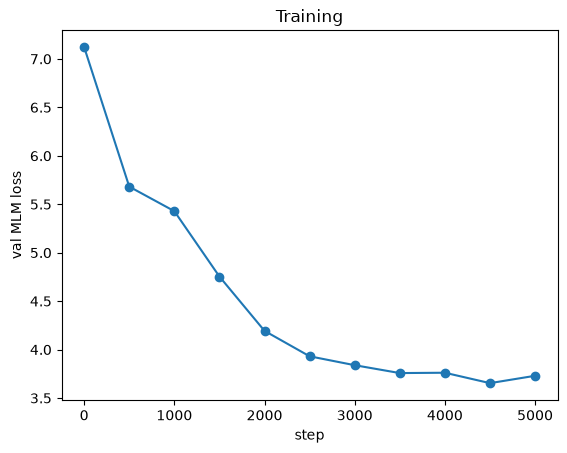

In [4]:
model = BERT(vocab_size, context_length, dim=128, n_blocks=4, n_heads=4, pad_id=PAD, dropout=0.1).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

steps, warmup = 5000, 200
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lambda s: min((s + 1) / warmup, 0.5 * (1 + math.cos(math.pi * s / steps))))

@torch.no_grad()
def evaluate(iters=20):
    model.eval()
    loss = correct = total = 0
    for _ in range(iters):
        x, labels = mask_tokens(get_batch("val"))
        logits = model(x)
        loss += F.cross_entropy(logits.view(-1, vocab_size), labels.view(-1)).item()
        target = labels != -100
        correct += (logits.argmax(-1)[target] == labels[target]).sum().item()
        total += target.sum().item()
    model.train()
    return loss / iters, correct / total

history, start = [], time.time()
model.train()
for step in range(steps + 1):
    if step % 500 == 0:
        val_loss, val_acc = evaluate()
        history.append((step, val_loss))
        print(f"step {step:4d} | val loss {val_loss:.3f} | masked-token accuracy {val_acc:.1%} | {time.time() - start:.0f}s")
    if step == steps:
        break
    x, labels = mask_tokens(get_batch("train"))
    loss = F.cross_entropy(model(x).view(-1, vocab_size), labels.view(-1))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    scheduler.step()

plt.plot(*zip(*history), marker="o"); plt.xlabel("step"); plt.ylabel("val MLM loss"); plt.title("Training")
plt.show()

## Fill in the blank

The sentences are batched together and padded to the same length with `[PAD]`. The **padding mask** keeps the real tokens from attending to the padding.

In [5]:
def encode_with_mask(sentence):
    before, after = sentence.split(" [MASK]")          # the mask absorbs the word's leading space
    return tok.encode(before) + [MASK] + tok.encode(after)

@torch.no_grad()
def fill_in(sentences, k=5):
    model.eval()
    seqs = [encode_with_mask(s) for s in sentences]
    width = max(map(len, seqs))
    batch = torch.tensor([s + [PAD] * (width - len(s)) for s in seqs], device=device)
    probs = F.softmax(model(batch), dim=-1)
    for s, seq, p in zip(sentences, seqs, probs):
        top = p[seq.index(MASK)].topk(k)
        guesses = ", ".join(f"{tok.vocab[i].decode(errors='replace')!r} {v:.0%}" for v, i in zip(top.values.tolist(), top.indices.tolist()))
        print(f"{s:55} -> {guesses}")

# each expected answer is a single BPE token, since one [MASK] predicts one token
fill_in([
    "He did not [MASK] what to say.",
    "The prince looked into her [MASK] and smiled.",
    "She went back into the [MASK] and shut the door.",
    "Socrates said that justice is the virtue of the [MASK].",
    "Shall I compare thee to a summer's [MASK]?",
])

He did not [MASK] what to say.                          -> ' know' 39%, ' see' 11%, ' think' 4%, ' say' 4%, ' understand' 4%
The prince looked into her [MASK] and smiled.           -> ',' 68%, ';' 7%, ' eyes' 2%, ' hand' 2%, ' mother' 1%
She went back into the [MASK] and shut the door.        -> ' room' 8%, ' time' 5%, ' house' 4%, ' day' 4%, ' world' 4%
Socrates said that justice is the virtue of the [MASK]. -> ' State' 24%, ' world' 14%, ' soul' 7%, ' knowledge' 5%, ' truth' 4%
Shall I compare thee to a summer's [MASK]?              -> 's' 3%, ' it' 3%, ' me' 3%, ' you' 2%, 'ion' 2%


## Why bidirectional matters

GPT predicting the blank would only see the words before it, which are identical within each pair below. BERT also sees the words *after* the blank, so its predictions can differ between them.

In [6]:
fill_in([
    "When [MASK] came home, she was very tired.",
    "When [MASK] came home, he was very tired.",
    "There [MASK] many people in the room.",
    "There [MASK] a man in the room.",
])

When [MASK] came home, she was very tired.              -> ',' 10%, ' to' 10%, ' she' 10%, ' had' 9%, ' he' 7%
When [MASK] came home, he was very tired.               -> ' he' 38%, ' had' 9%, ' was' 5%, ' to' 5%, ',' 5%
There [MASK] many people in the room.                   -> ' was' 13%, 'ed' 4%, ' is' 3%, 'ady' 3%, ' had' 3%
There [MASK] a man in the room.                         -> ' was' 15%, 'w' 7%, ' is' 7%, ' had' 6%, ' of' 5%


**Result:** the pronoun pair shows that context *after* the blank is used. With `..., he was very tired` the model puts 38% on ` he` and ` she` doesn't make the top 5. With `..., she was very tired`, ` she` rises to the top 3. The `was`/`were` pair isn't learned: this 1M-parameter model trained for 24 CPU-minutes predicts ` was` for both. Real BERT-base is about 100x larger and trained for days.

## Encoder self-attention

There's no triangle: every token attends to tokens on both sides. Heads in the last layer, for one sentence:

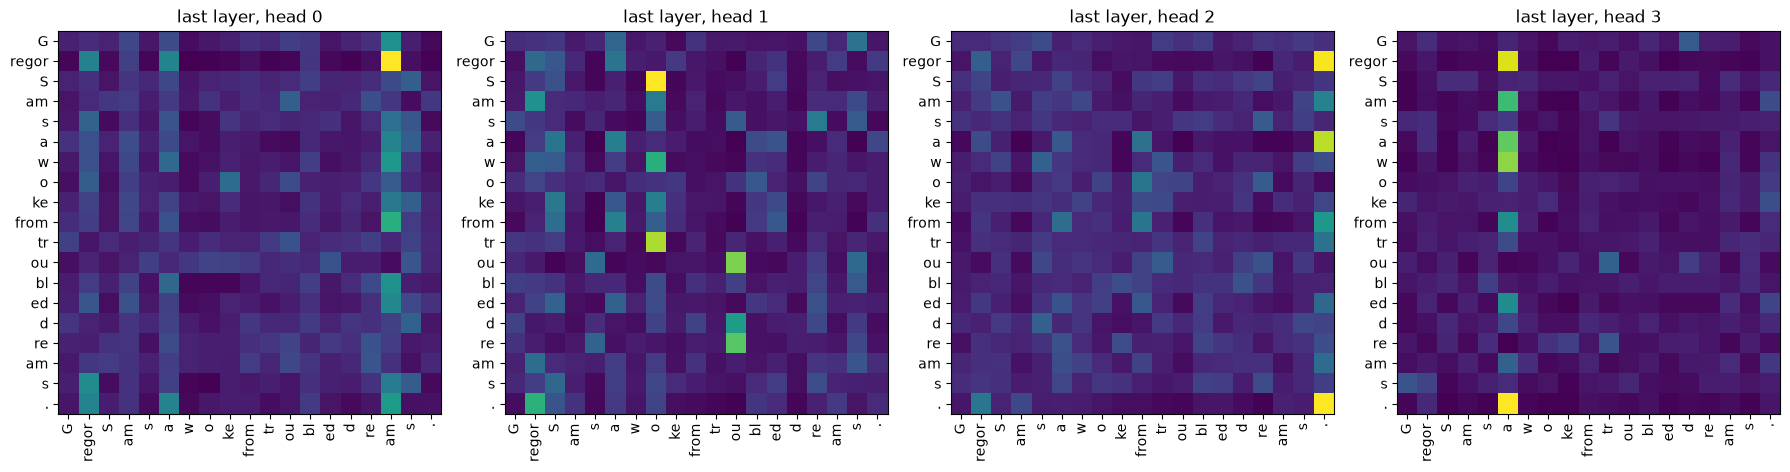

In [7]:
sentence = "Gregor Samsa woke from troubled dreams."
labels = tok.pieces(sentence)
model.eval()
with torch.no_grad():
    model(torch.tensor([tok.encode(sentence)], device=device))
weights = model.blocks[-1].self_attn.attn_weights[0].cpu()
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for h, ax in enumerate(axes):
    ax.imshow(weights[h], cmap="viridis")
    ax.set_title(f"last layer, head {h}")
    ax.set_xticks(range(len(labels)), labels, rotation=90); ax.set_yticks(range(len(labels)), labels)
plt.tight_layout(); plt.show()